In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
df = pd.read_csv("../data/energy_data_set.csv")

In [43]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [44]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
T1,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
RH_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
T2,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
RH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
T3,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
RH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
T4,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
RH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9  

In [46]:
df.duplicated().sum()

0

In [47]:
df.isnull().sum().sum()

0

In [48]:
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d %H:%M:%S").astype("datetime64[s]")
df = df.set_index("date").sort_index()

In [49]:
(df.index.to_series().diff().dropna() != pd.Timedelta(minutes=10)).sum()

0

Skewness: 3.3863672147430632


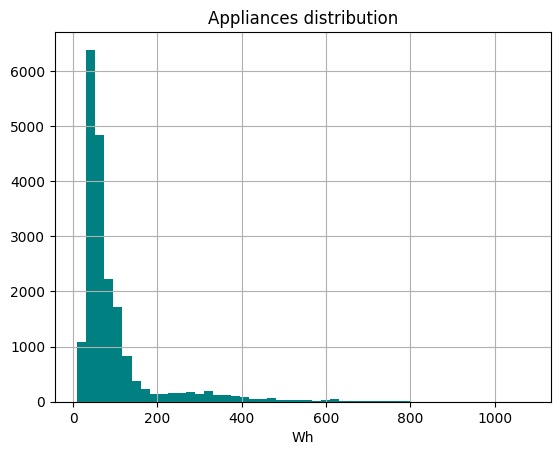

In [50]:
print("Skewness:", df["Appliances"].skew())

df["Appliances"].hist(bins=50, color="teal")
plt.title("Appliances distribution")
plt.xlabel("Wh")
plt.show()

In [51]:
Q1 = df["Appliances"].quantile(0.25)
Q3 = df["Appliances"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["Appliances"] < lower_bound) | (df["Appliances"] > upper_bound)]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outlier Count:", len(outliers))
print("Outlier Percentage:", round(len(outliers) / len(df) * 100, 2), "%")

Lower Bound: -25.0
Upper Bound: 175.0
Outlier Count: 2138
Outlier Percentage: 10.83 %


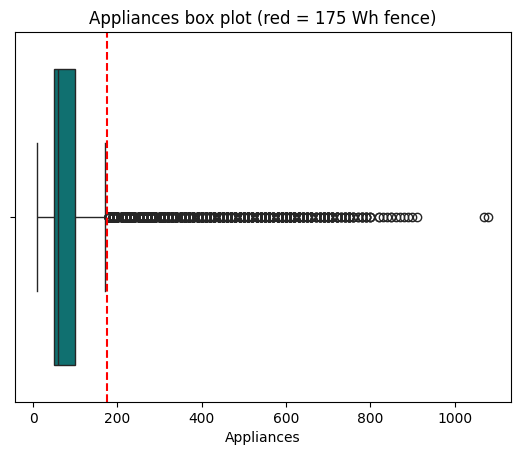

In [52]:
sns.boxplot(x=df["Appliances"], color="teal")
plt.axvline(upper_bound, color="red", linestyle="--")
plt.title("Appliances box plot (red = 175 Wh fence)")
plt.show()

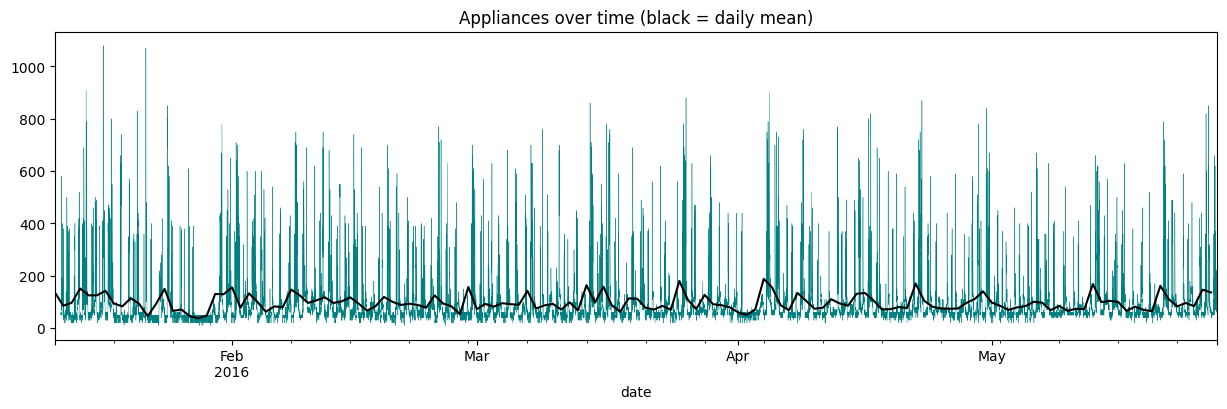

In [53]:
df["Appliances"].plot(figsize=(15, 4), color="teal", linewidth=0.3)
df["Appliances"].resample("D").mean().plot(color="black")
plt.title("Appliances over time (black = daily mean)")
plt.show()

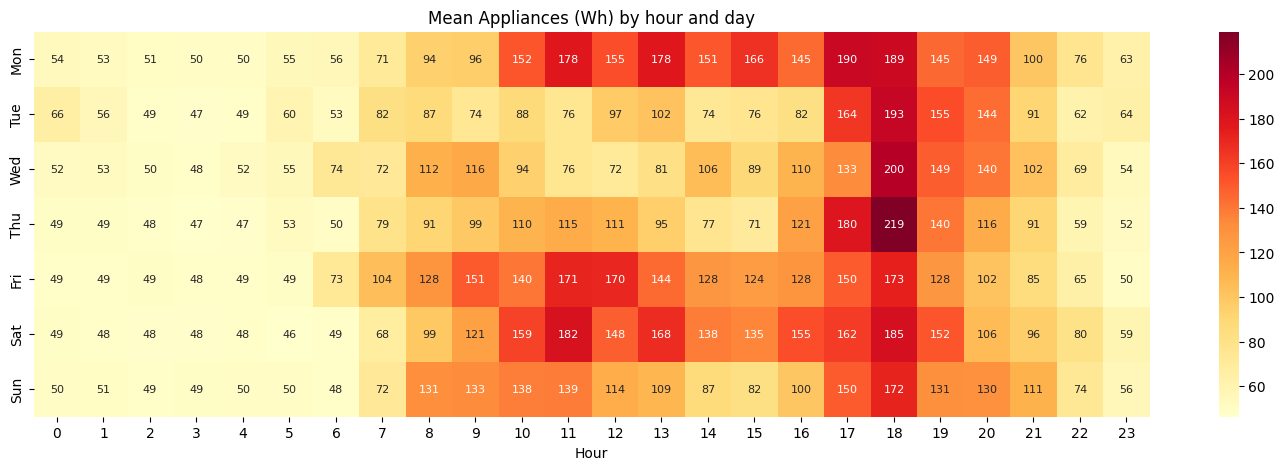

In [89]:
pivot = df.pivot_table(values="Appliances", index=df.index.dayofweek, columns=df.index.hour, aggfunc="mean")
pivot.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(18, 5))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 8})
plt.xlabel("Hour")
plt.ylabel("")
plt.title("Mean Appliances (Wh) by hour and day")
plt.show()

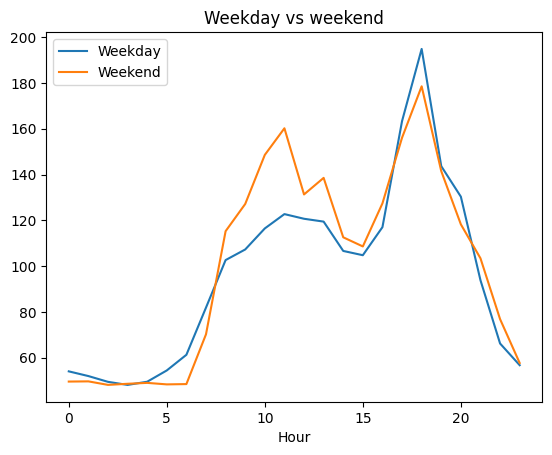

In [55]:
weekend = df.index.dayofweek >= 5

df[~weekend].groupby(df[~weekend].index.hour)["Appliances"].mean().plot(label="Weekday")
df[weekend].groupby(df[weekend].index.hour)["Appliances"].mean().plot(label="Weekend")
plt.xlabel("Hour")
plt.title("Weekday vs weekend")
plt.legend()
plt.show()

In [56]:
df.groupby(df.index.dayofweek)["Appliances"].agg(["mean", "median", "std", "max"]).round(2)

,mean,median,std,max
date,,,,
0,111.45,60.0,122.12,900
1,87.12,60.0,90.98,770
2,89.93,70.0,80.73,830
3,90.43,60.0,98.31,1070
4,104.62,60.0,116.25,880
5,106.25,70.0,110.22,1080
6,94.92,60.0,90.51,850


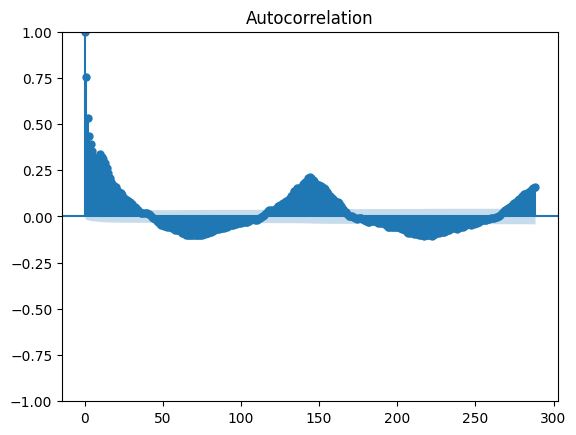

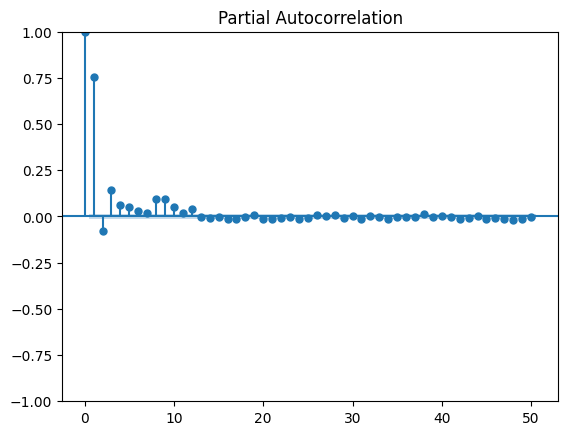

1 0.753
2 0.534
3 0.438
6 0.324
18 0.171
36 0.021
144 0.217


In [57]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(df["Appliances"], lags=288)
plt.show()

plot_pacf(df["Appliances"], lags=50)
plt.show()

for lag in [1, 2, 3, 6, 18, 36, 144]:
    print(lag, round(df["Appliances"].autocorr(lag), 3))

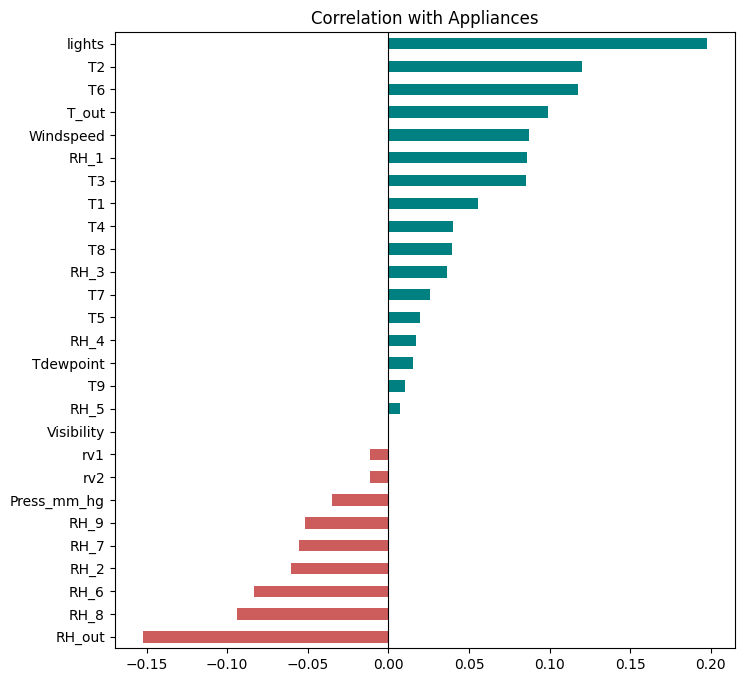

In [90]:
corr = df.corr()["Appliances"].drop("Appliances").sort_values()

colors = ["indianred" if value < 0 else "teal" for value in corr]
corr.plot(kind="barh", figsize=(8, 8), color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation with Appliances")
plt.show()

In [59]:
daily = df.resample("D").mean()
print(daily["Appliances"].corr(daily["T_out"]))

0.007110894372498219


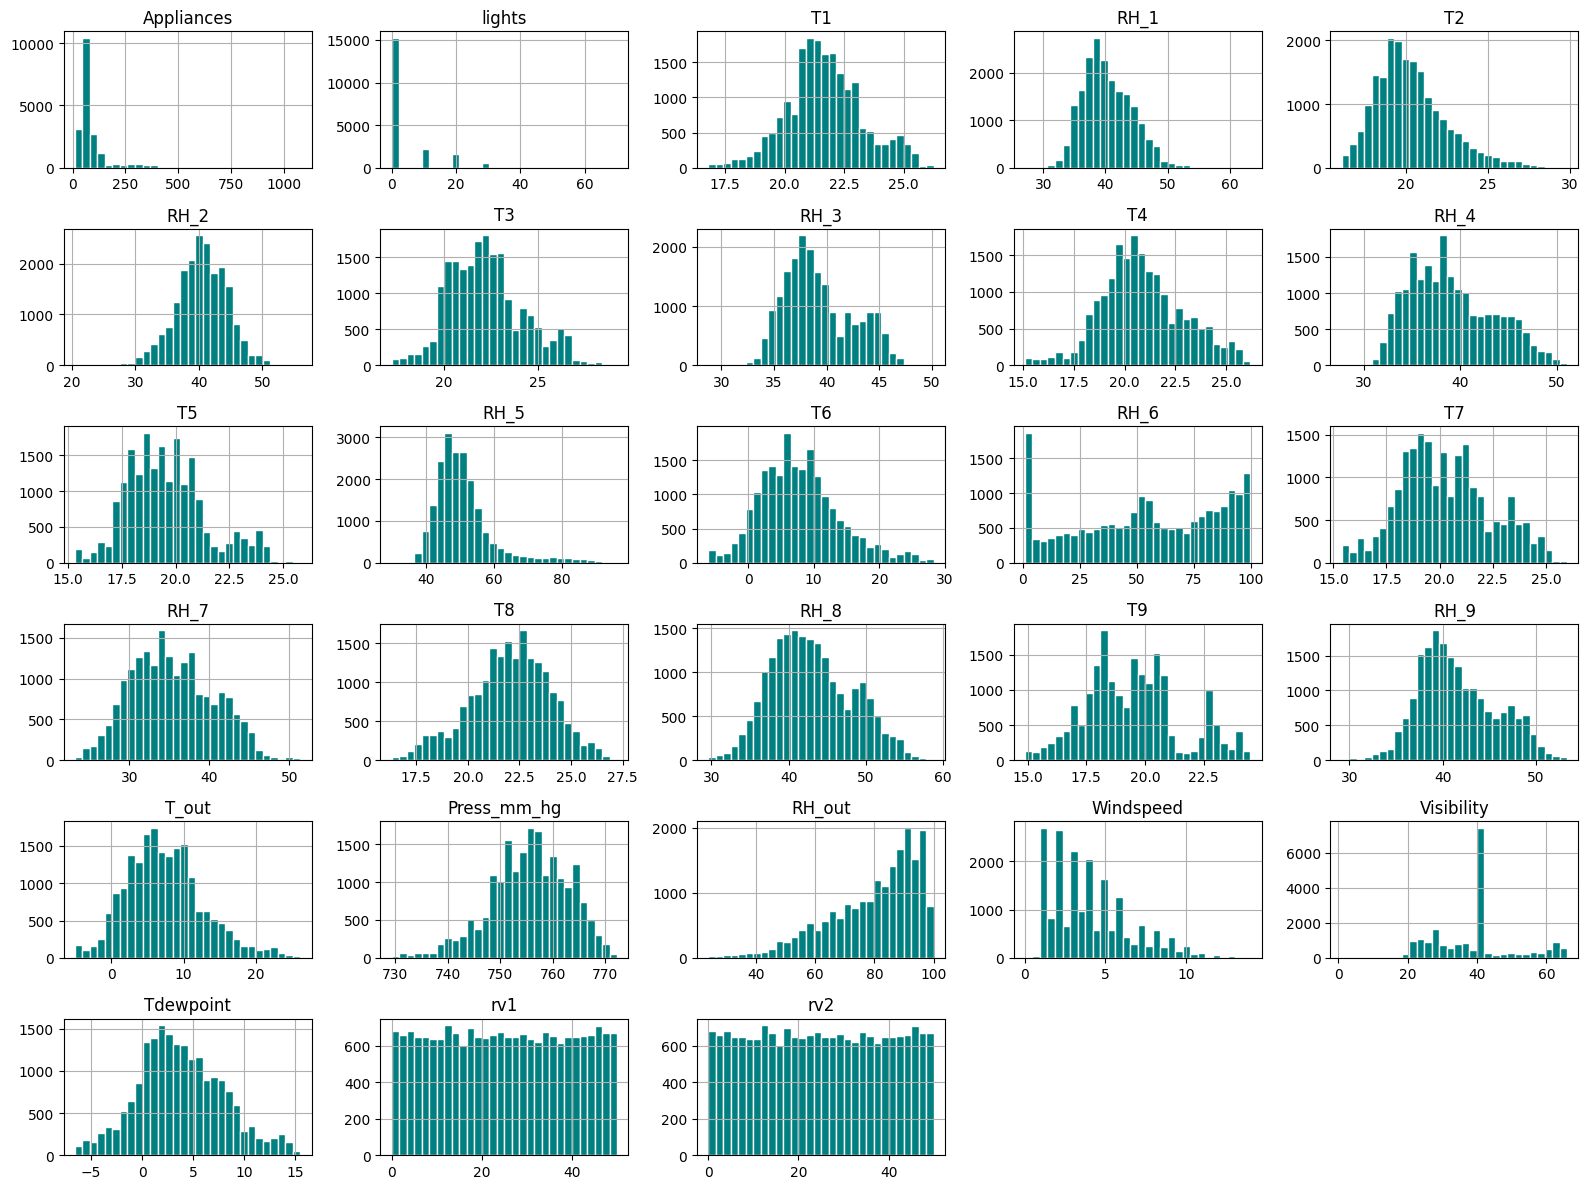

In [60]:
df.hist(figsize=(16, 12), bins=30, layout=(6, 5), color="teal", edgecolor="white")
plt.tight_layout()
plt.savefig("../reports/feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

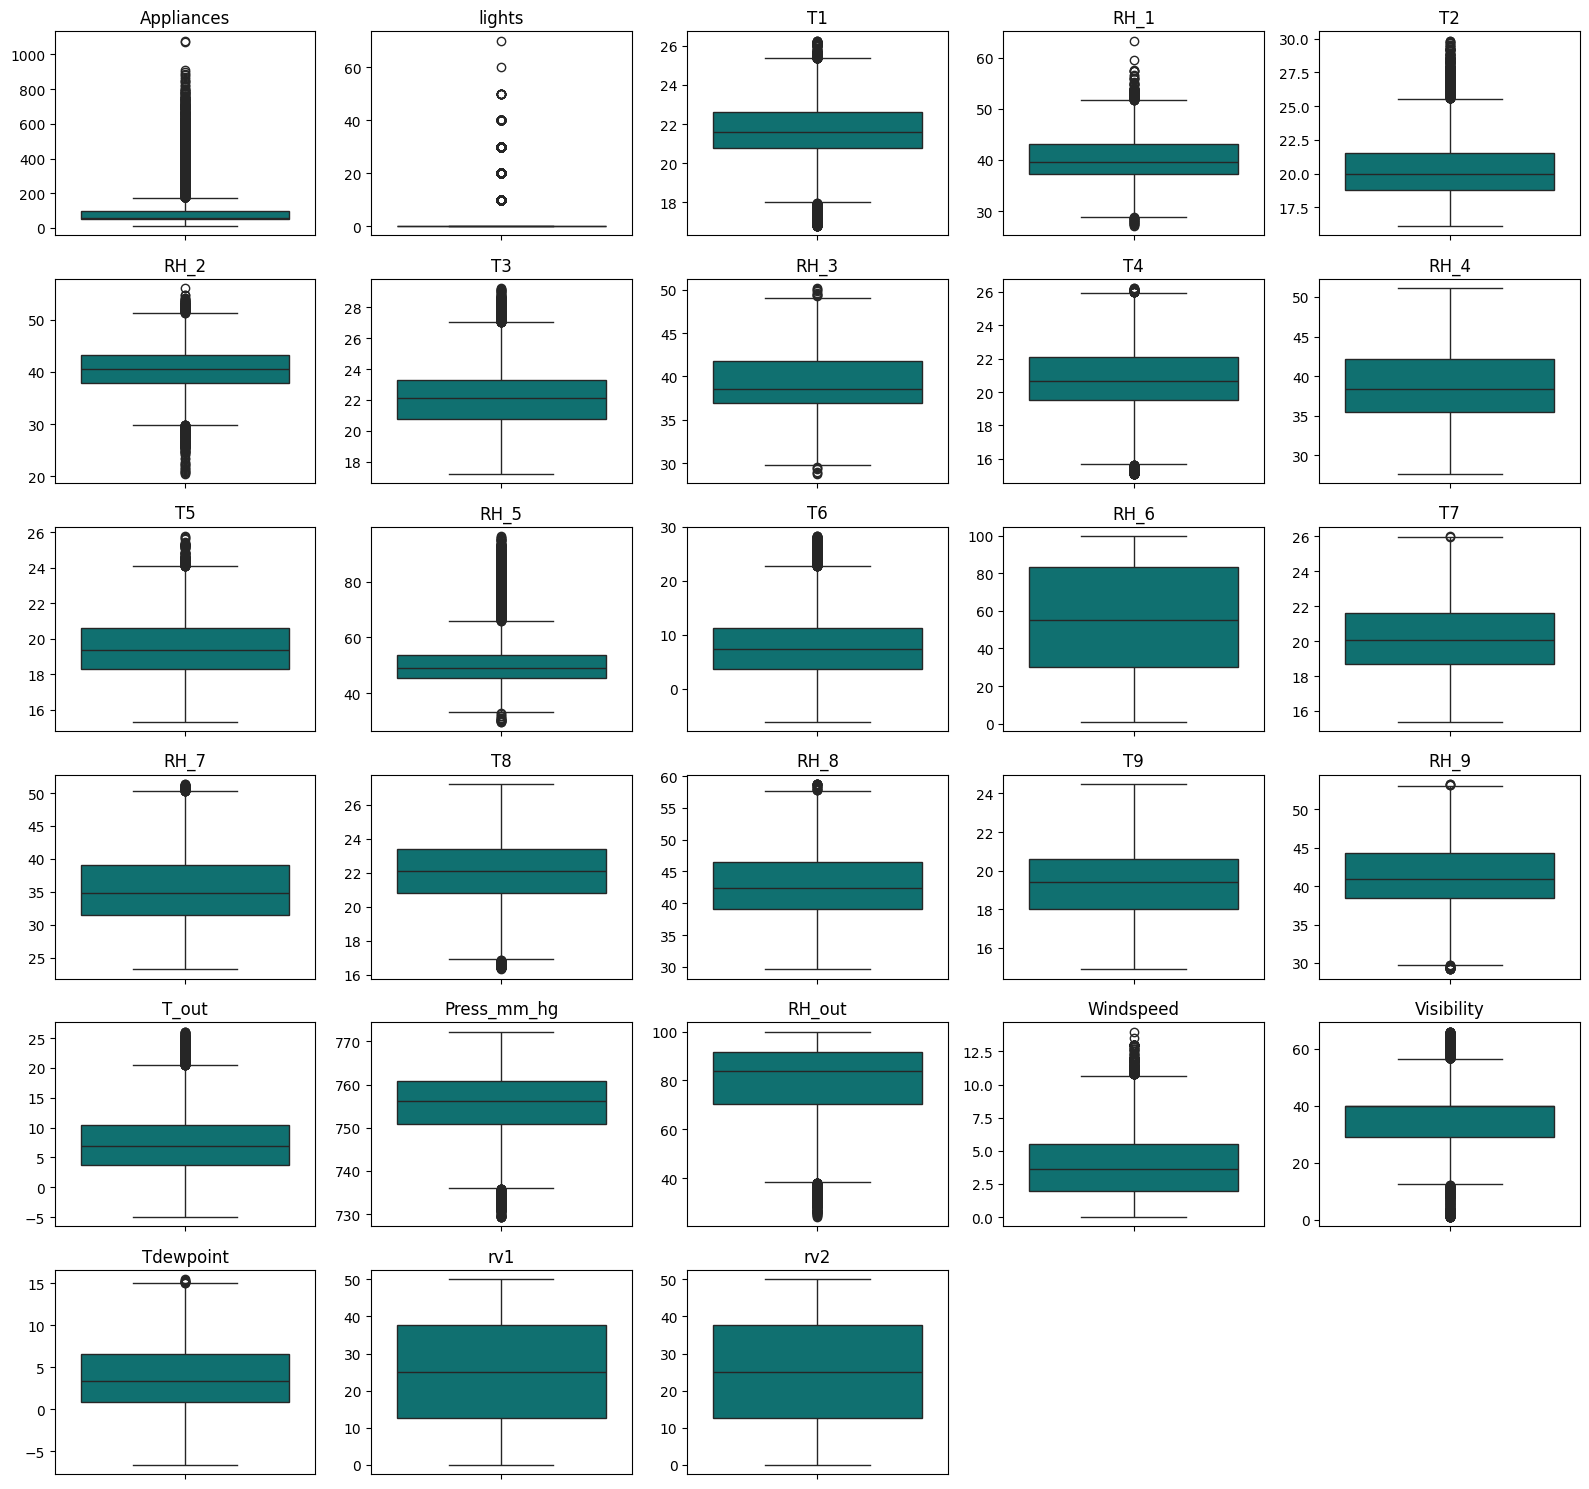

In [61]:
fig, axes = plt.subplots(6, 5, figsize=(16, 15))

for ax, column in zip(axes.flat, df.columns):
    sns.boxplot(y=df[column], ax=ax, color="teal")
    ax.set_title(column)
    ax.set_ylabel("")

for ax in axes.flat[len(df.columns):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [62]:
print((df["lights"] == 0).mean())

0.7728401317456296


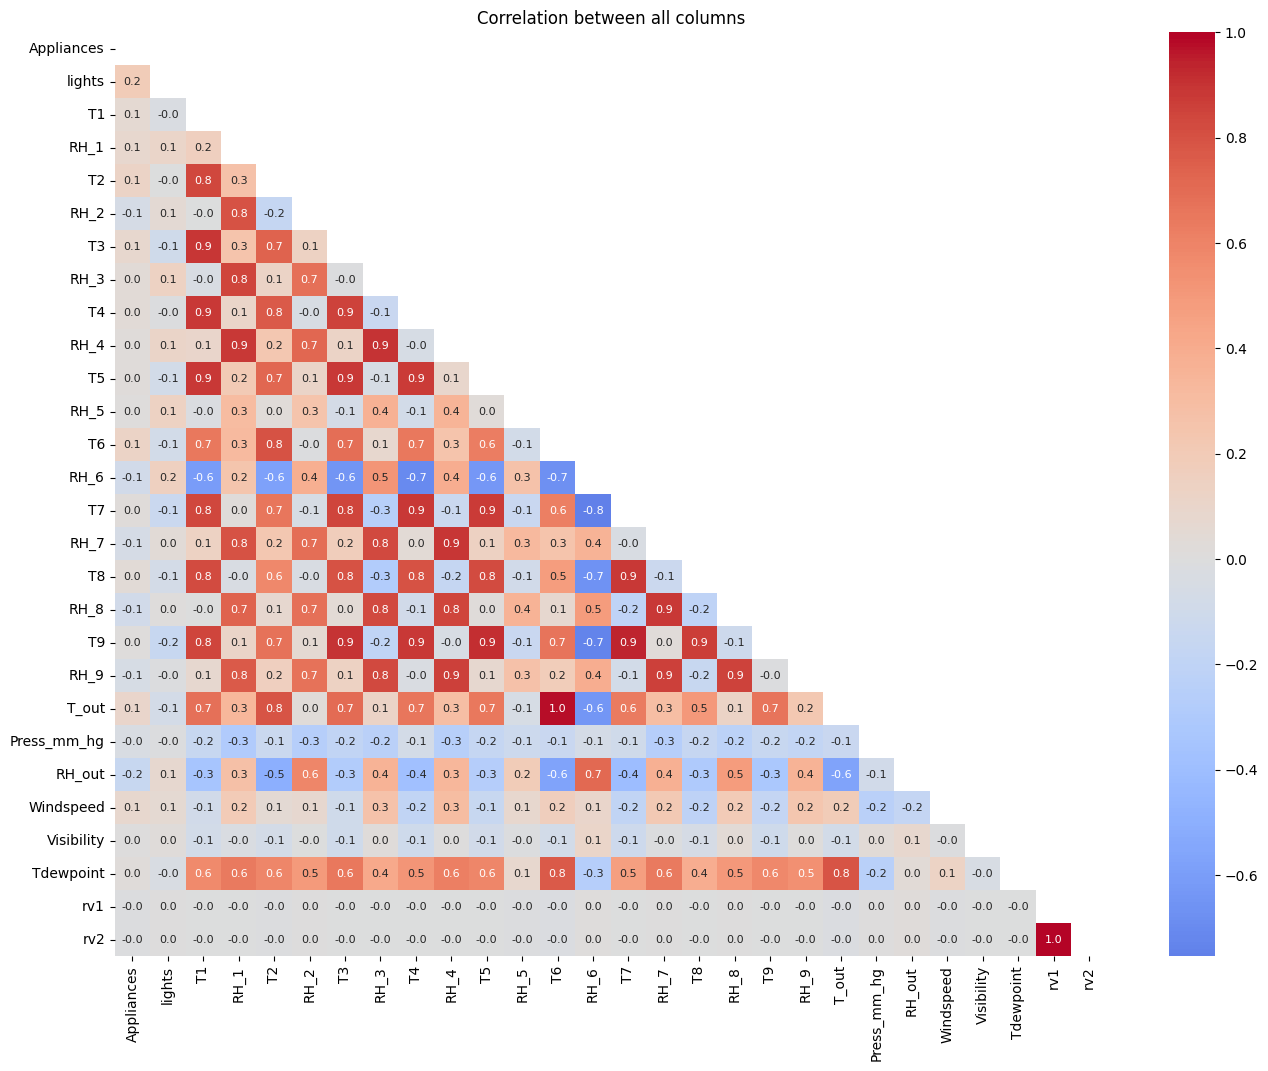

In [88]:
corr_matrix = df.corr()
mask = np.triu(np.ones(corr_matrix.shape, dtype=bool))

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".1f", annot_kws={"size": 8},
            cmap="coolwarm", center=0)
plt.title("Correlation between all columns")
plt.show()

In [64]:
print(df["T6"].corr(df["T_out"]))

0.9747866900664538


In [65]:
print((df["rv1"] == df["rv2"]).all())
print(df["rv1"].corr(df["Appliances"]))

True
-0.01114491753363445


In [66]:
from pathlib import Path
Path("data").mkdir(parents=True, exist_ok=True)
df.to_parquet("data/eda.parquet")

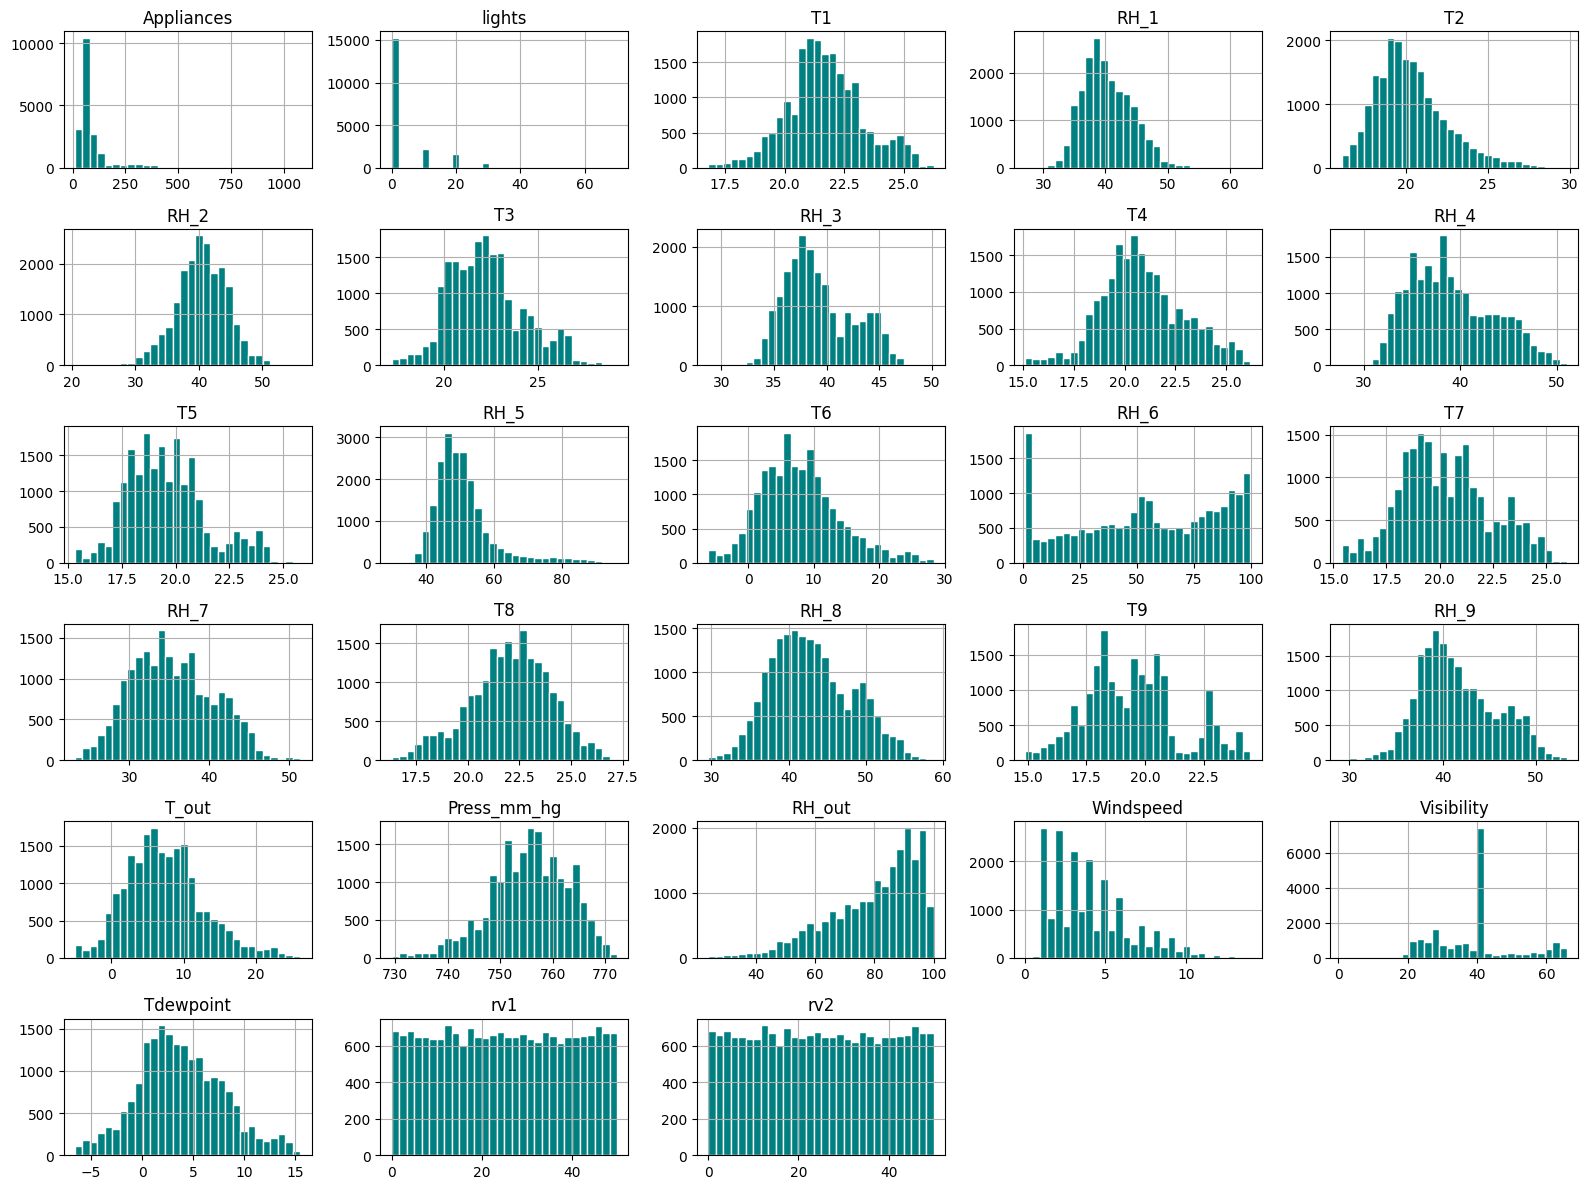

In [67]:
df.hist(figsize=(16, 12), bins=30, layout=(6, 5), color="teal", edgecolor="white")
plt.tight_layout()
plt.savefig("../reports/feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

Skewness: 3.3863672147430632


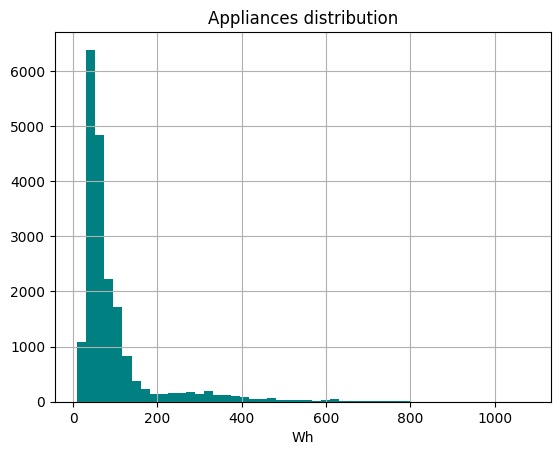

In [68]:
print("Skewness:", df["Appliances"].skew())

df["Appliances"].hist(bins=50, color="teal")
plt.title("Appliances distribution")
plt.xlabel("Wh")
plt.show()

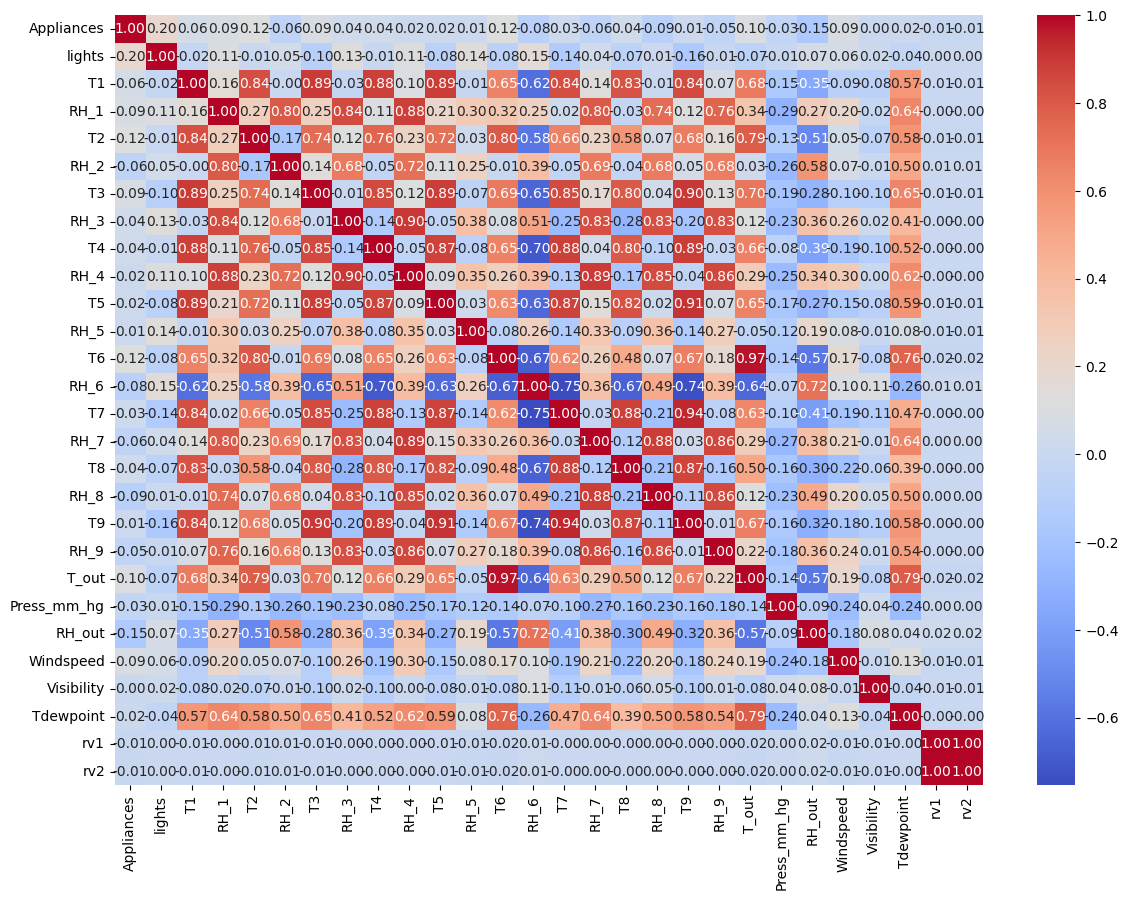

In [69]:
import seaborn as sns

corr_matrix = df.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 10})
plt.show()

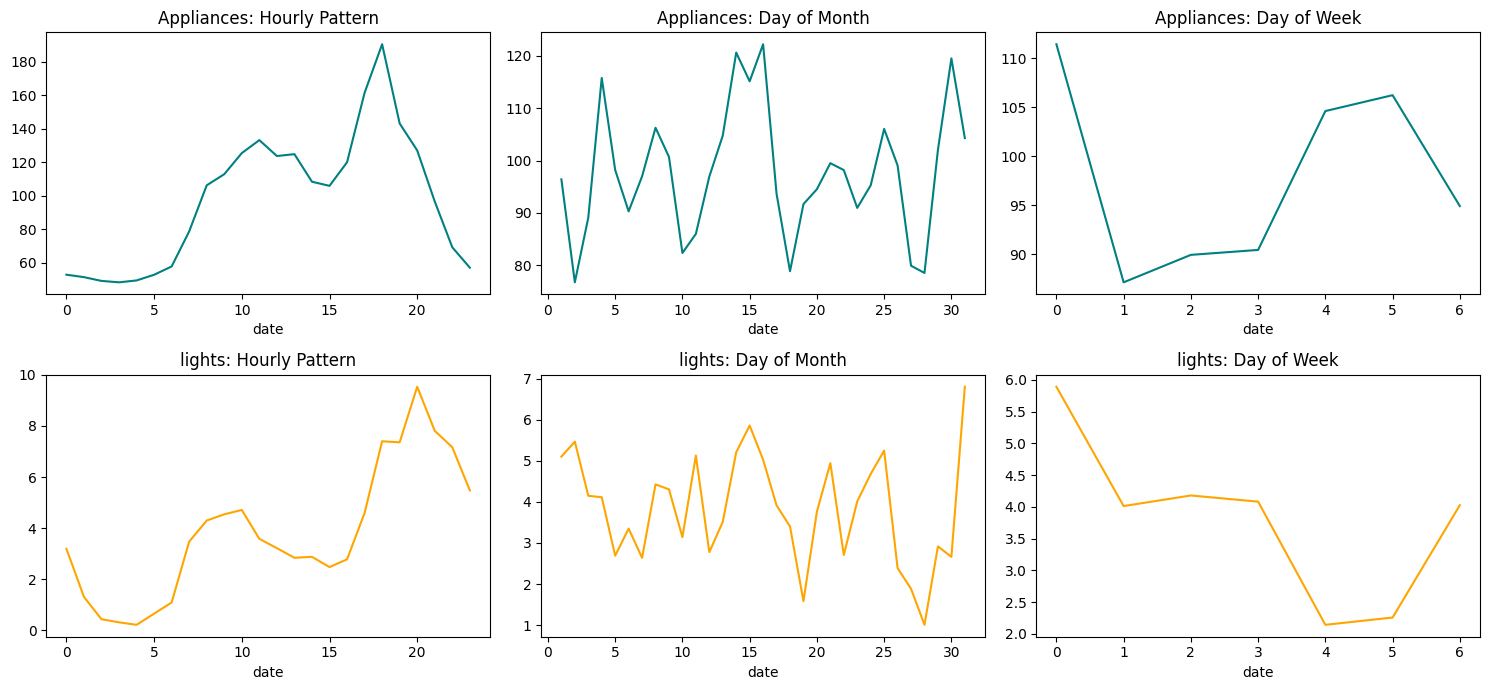

In [70]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for i, column in enumerate(["Appliances", "lights"]):
    color = "teal" if column == "Appliances" else "orange"
    df.groupby(df.index.hour)[column].mean().plot(ax=axes[i, 0], color=color, title=f"{column}: Hourly Pattern")
    df.groupby(df.index.day)[column].mean().plot(ax=axes[i, 1], color=color, title=f"{column}: Day of Month")
    df.groupby(df.index.dayofweek)[column].mean().plot(ax=axes[i, 2], color=color, title=f"{column}: Day of Week")

plt.tight_layout()
plt.show()

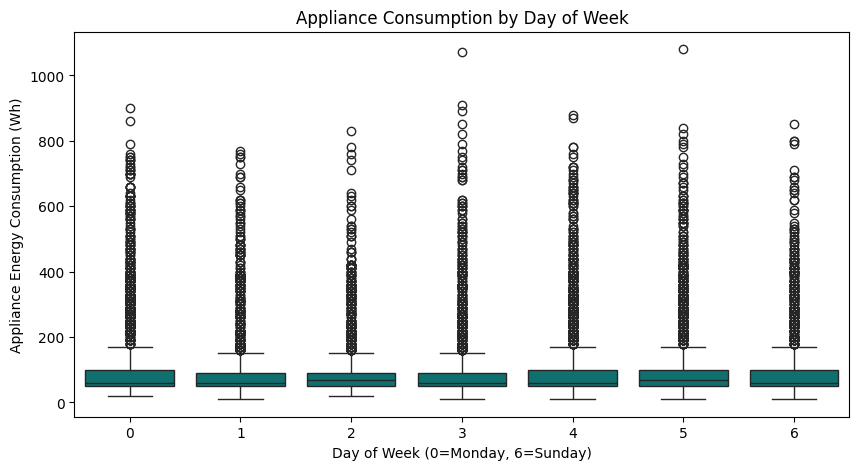

In [71]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df.index.dayofweek, y=df["Appliances"], color="teal")
plt.xlabel("Day of Week (0=Monday, 6=Sunday)")
plt.ylabel("Appliance Energy Consumption (Wh)")
plt.title("Appliance Consumption by Day of Week")
plt.show()

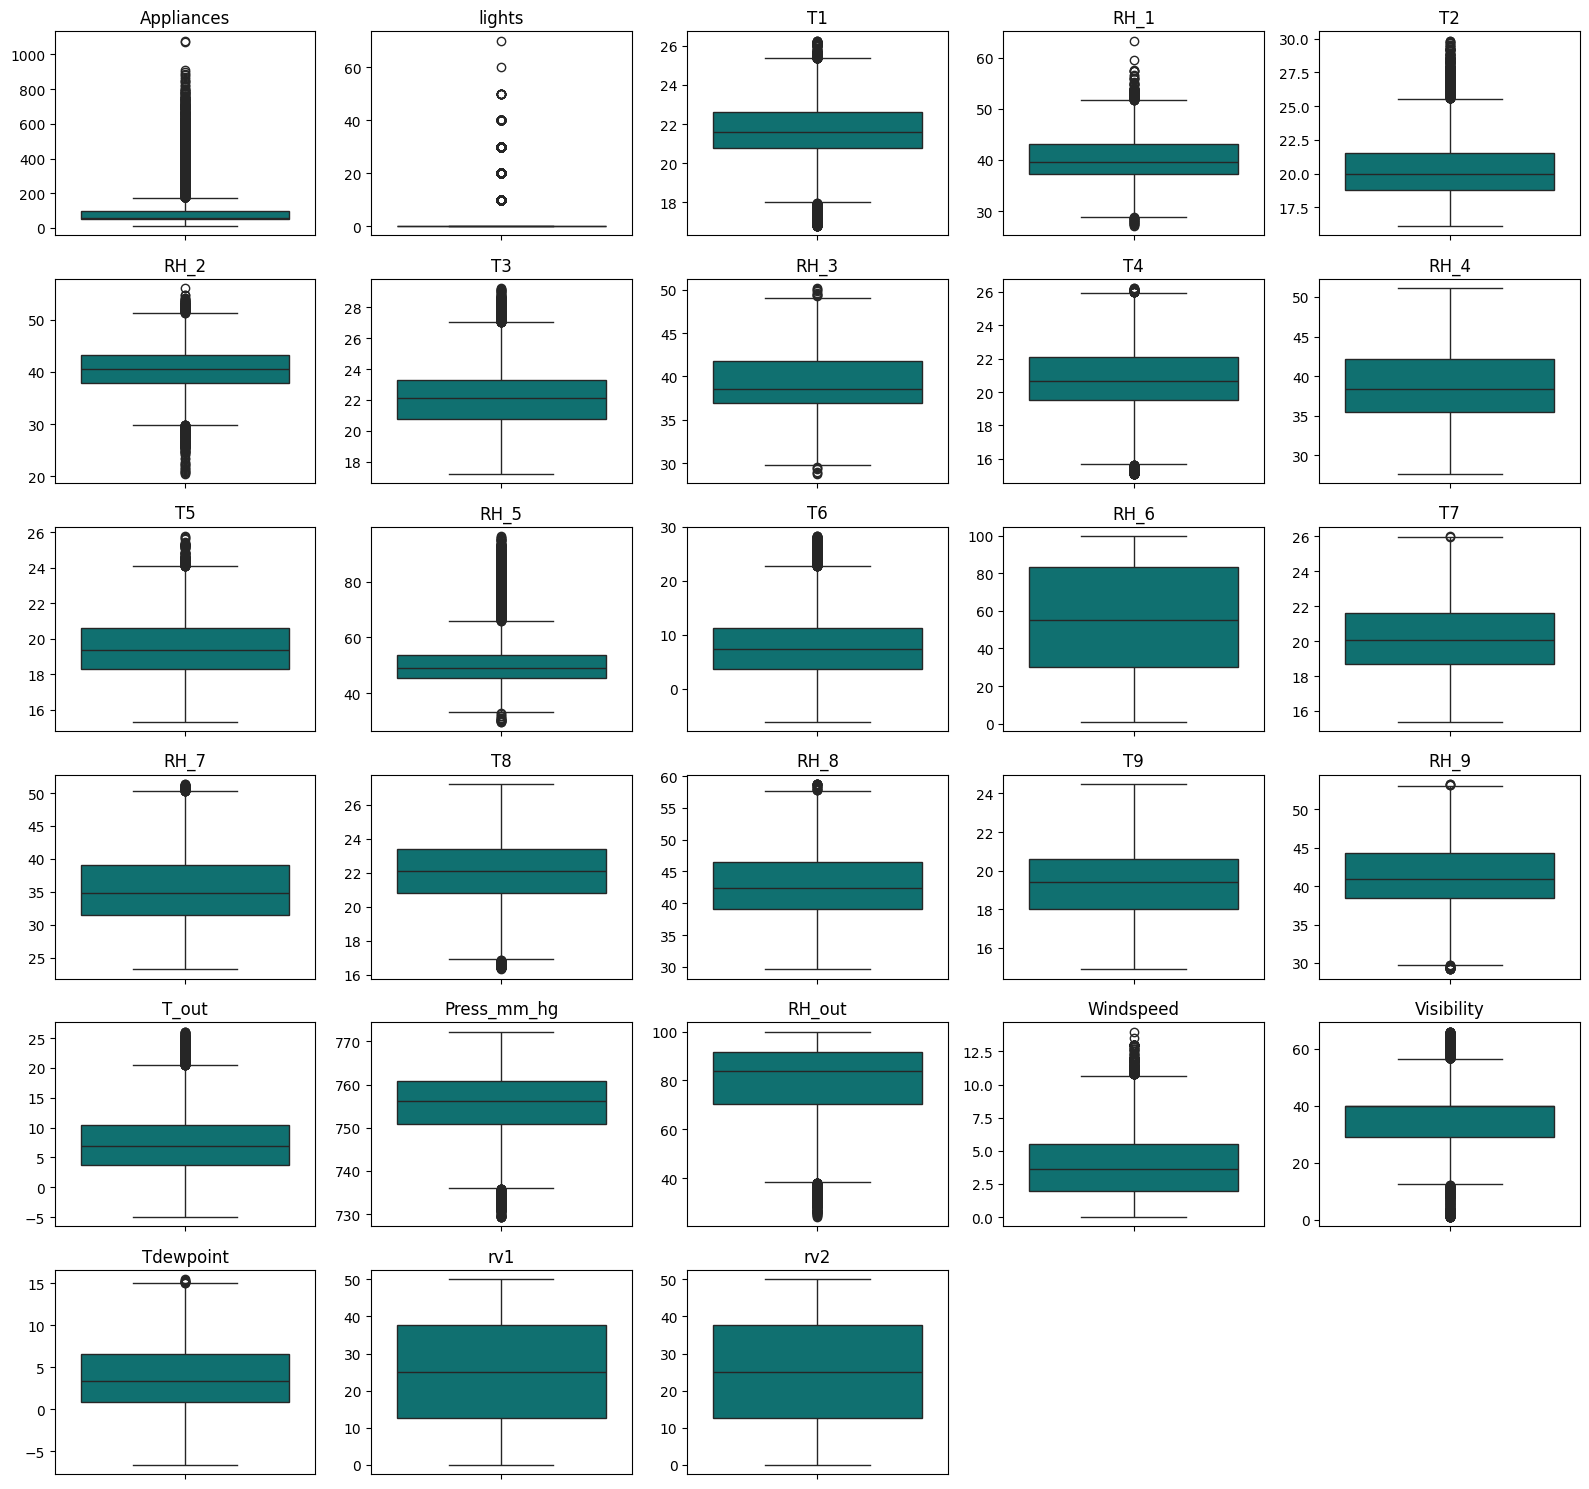

In [72]:
fig, axes = plt.subplots(6, 5, figsize=(16, 15))

for ax, column in zip(axes.flat, df.columns):
    sns.boxplot(y=df[column], ax=ax, color="teal")
    ax.set_title(column)
    ax.set_ylabel("")

for ax in axes.flat[len(df.columns):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [73]:
df.groupby(df.index.dayofweek)["Appliances"].agg(["mean", "median", "std", "max"]).round(2)

,mean,median,std,max
date,,,,
0,111.45,60.0,122.12,900
1,87.12,60.0,90.98,770
2,89.93,70.0,80.73,830
3,90.43,60.0,98.31,1070
4,104.62,60.0,116.25,880
5,106.25,70.0,110.22,1080
6,94.92,60.0,90.51,850


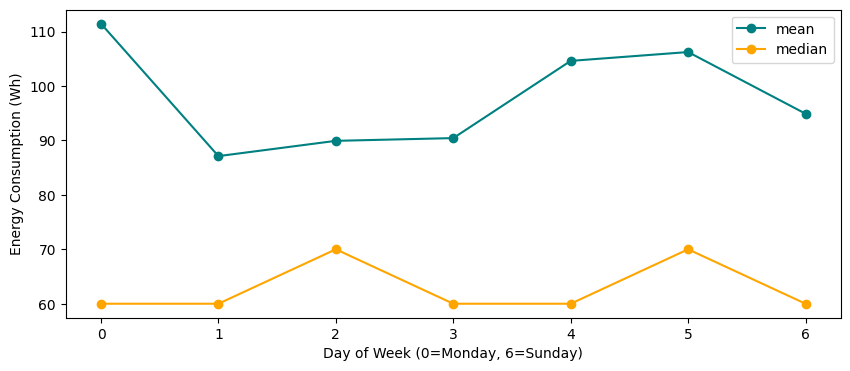

In [74]:
weekly = df.groupby(df.index.dayofweek)["Appliances"].agg(["mean", "median"])

weekly.plot(figsize=(10, 4), color=["teal", "orange"], marker="o")
plt.xlabel("Day of Week (0=Monday, 6=Sunday)")
plt.ylabel("Energy Consumption (Wh)")
plt.show()

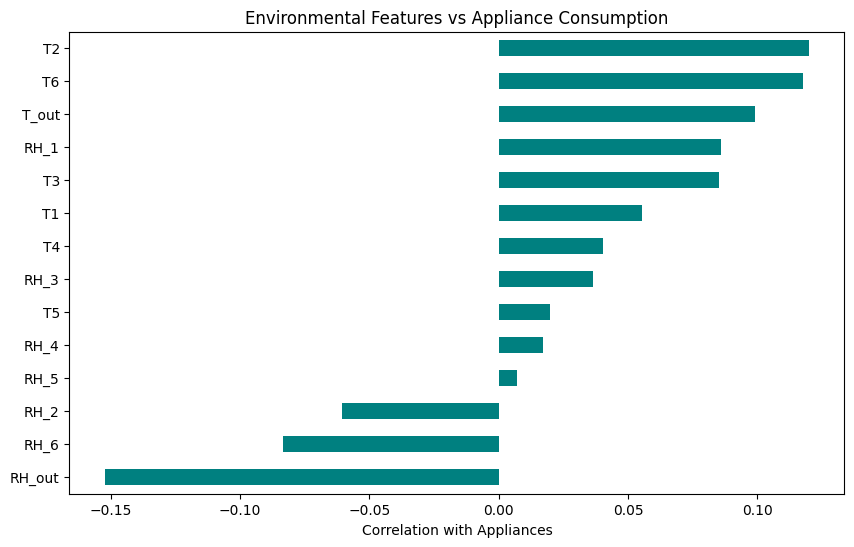

In [75]:
columns = ["Appliances", "T1", "T2", "T3", "T4", "T5", "T6", "RH_1", "RH_2", "RH_3", "RH_4", "RH_5", "RH_6", "T_out", "RH_out"]

corr = df[columns].corr()["Appliances"].drop("Appliances").sort_values()

corr.plot(kind="barh", figsize=(10, 6), color="teal")
plt.xlabel("Correlation with Appliances")
plt.title("Environmental Features vs Appliance Consumption")
plt.show()

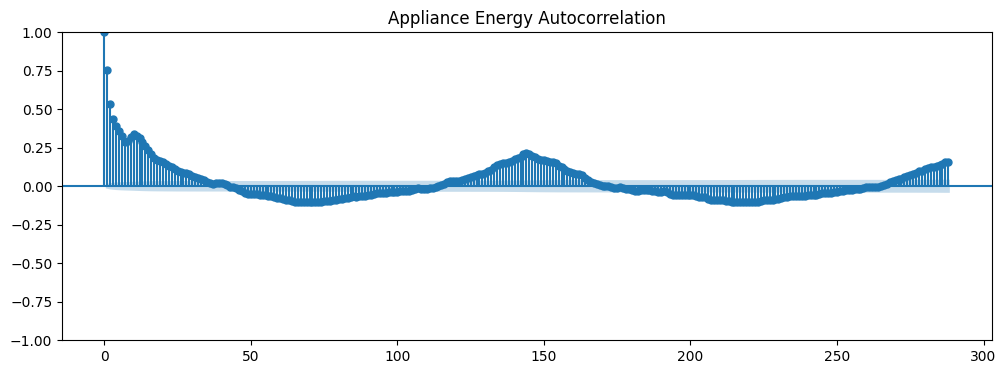

In [76]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df["Appliances"].dropna(), lags=288, ax=ax)
plt.title("Appliance Energy Autocorrelation")
plt.show()

In [77]:
Q1 = df["Appliances"].quantile(0.25)
Q3 = df["Appliances"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["Appliances"] < lower_bound) | (df["Appliances"] > upper_bound)]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Outlier Count:", len(outliers))
print("Outlier Percentage:", round(len(outliers) / len(df) * 100, 2), "%")

Lower Bound: -25.0
Upper Bound: 175.0
Outlier Count: 2138
Outlier Percentage: 10.83 %


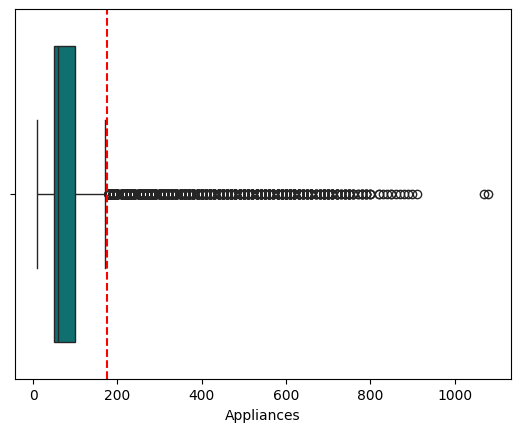

In [78]:
sns.boxplot(x=df["Appliances"], color="teal")
plt.axvline(upper_bound, color="red", linestyle="--")
plt.show()

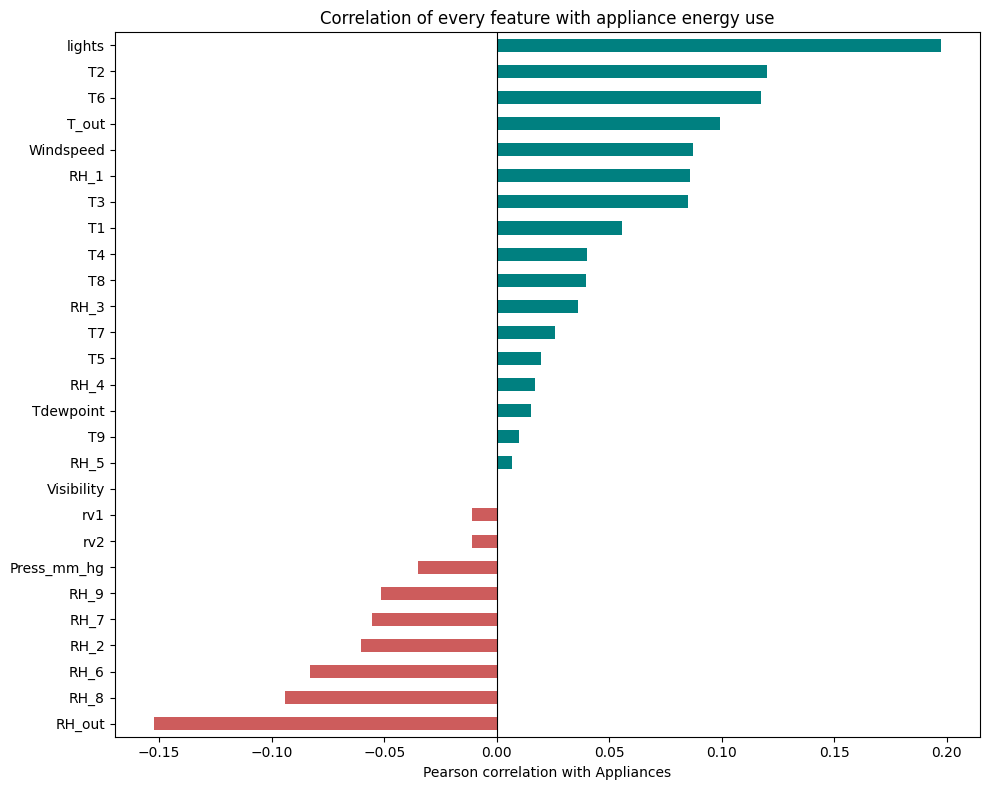

lights    0.197
RH_out   -0.152
T2        0.120
T6        0.118
T_out     0.099
Name: Appliances, dtype: float64

In [79]:
target_corr = df.corr()["Appliances"].drop("Appliances").sort_values()

colors = ["teal" if value > 0 else "indianred" for value in target_corr]
target_corr.plot(kind="barh", figsize=(10, 8), color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson correlation with Appliances")
plt.title("Correlation of every feature with appliance energy use")
plt.tight_layout()
plt.show()

target_corr.sort_values(key=abs, ascending=False).head(5).round(3)

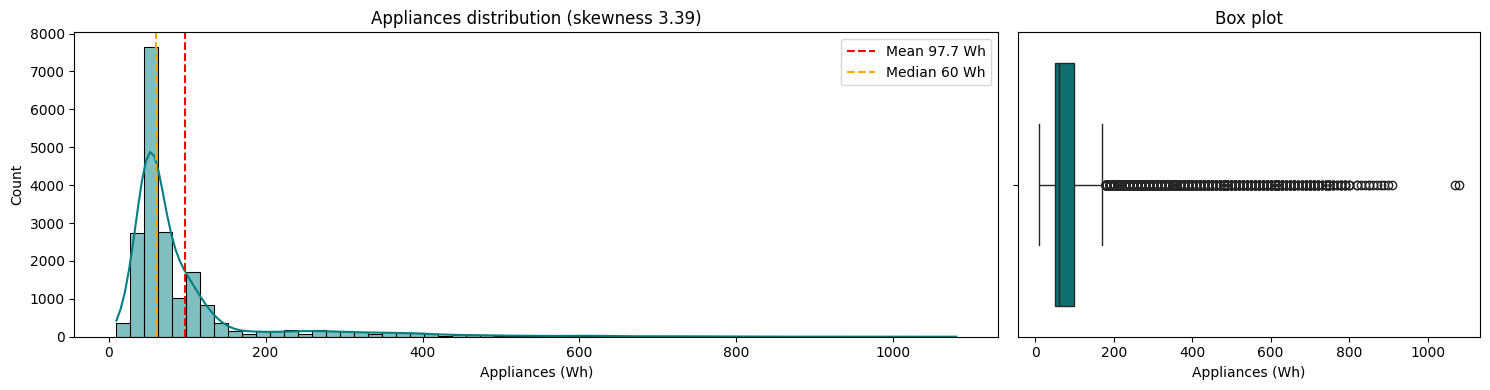

mean          97.69
median        60.00
std          102.52
min           10.00
max         1080.00
skewness       3.39
kurtosis      13.67
dtype: float64

In [80]:
y = df["Appliances"]
target_stats = pd.Series({
    "mean": y.mean(), "median": y.median(), "std": y.std(),
    "min": y.min(), "max": y.max(),
    "skewness": y.skew(), "kurtosis": y.kurt(),
}).round(2)

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(y, bins=60, kde=True, color="teal", ax=axes[0])
axes[0].axvline(y.mean(), color="red", linestyle="--", label=f"Mean {y.mean():.1f} Wh")
axes[0].axvline(y.median(), color="orange", linestyle="--", label=f"Median {y.median():.0f} Wh")
axes[0].set(title=f"Appliances distribution (skewness {y.skew():.2f})", xlabel="Appliances (Wh)")
axes[0].legend()
sns.boxplot(x=y, color="teal", ax=axes[1])
axes[1].set(title="Box plot", xlabel="Appliances (Wh)")
plt.tight_layout()
plt.show()

target_stats

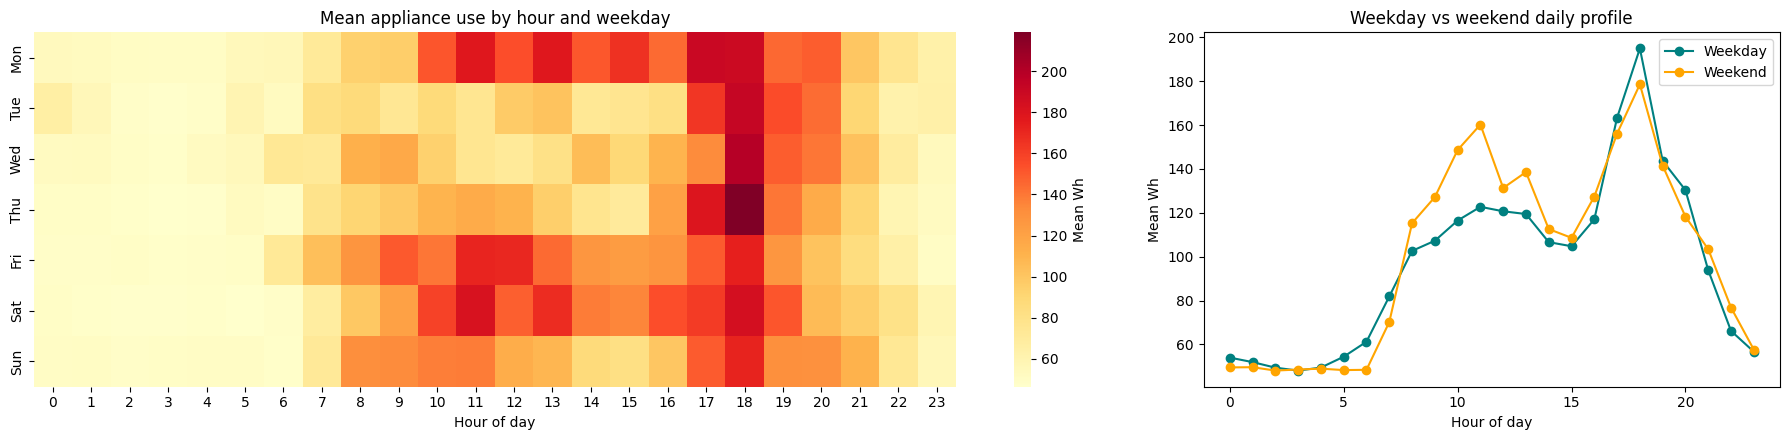

Peak hour (all days): 18


In [81]:
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
hour_by_day = df.groupby([df.index.dayofweek, df.index.hour])["Appliances"].mean().unstack()
hour_by_day.index = day_names

day_type = np.where(df.index.dayofweek >= 5, "Weekend", "Weekday")
weekday_vs_weekend = df.groupby([day_type, df.index.hour])["Appliances"].mean().unstack(0)

fig, axes = plt.subplots(1, 2, figsize=(18, 4.5), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap(hour_by_day, cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "Mean Wh"})
axes[0].set(title="Mean appliance use by hour and weekday", xlabel="Hour of day", ylabel="")
weekday_vs_weekend.plot(ax=axes[1], marker="o", color=["teal", "orange"])
axes[1].set(title="Weekday vs weekend daily profile", xlabel="Hour of day", ylabel="Mean Wh")
plt.tight_layout()
plt.show()

print("Peak hour (all days):", df.groupby(df.index.hour)["Appliances"].mean().idxmax())

In [82]:
weekend = df.index.dayofweek >= 5

print("rv1 identical to rv2 in every row:", (df["rv1"] == df["rv2"]).all())
print(f"Correlation with Appliances: rv1 {df['rv1'].corr(df['Appliances']):.3f}, rv2 {df['rv2'].corr(df['Appliances']):.3f}")
print(f"lights is 0 in {(df['lights'] == 0).mean():.0%} of rows")
print(f"Mean use: weekdays {df.loc[~weekend, 'Appliances'].mean():.1f} Wh, weekends {df.loc[weekend, 'Appliances'].mean():.1f} Wh")

rv1 identical to rv2 in every row: True
Correlation with Appliances: rv1 -0.011, rv2 -0.011
lights is 0 in 77% of rows
Mean use: weekdays 96.6 Wh, weekends 100.6 Wh


In [83]:
def iqr_outlier_share(column):
    """Percentage of values outside the 1.5 × IQR fences."""
    q1, q3 = column.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((column < q1 - 1.5 * iqr) | (column > q3 + 1.5 * iqr)).mean() * 100

outlier_share = df.apply(iqr_outlier_share).sort_values(ascending=False).round(2)
outlier_share.rename("% outside IQR fences").head(10)

lights        22.72
Visibility    12.78
Appliances    10.83
RH_5           6.74
T2             2.77
T1             2.61
T6             2.61
T_out          2.21
RH_out         1.21
RH_2           1.19
Name: % outside IQR fences, dtype: float64

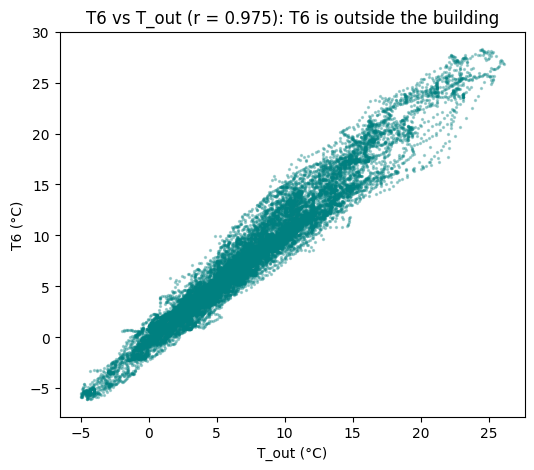

rv1  rv2      1.000
T6   T_out    0.975
T7   T9       0.945
T5   T9       0.911
T3   T9       0.901
Name: abs correlation, dtype: float64

In [84]:
feature_corr = df.drop(columns="Appliances").corr().abs()
upper_triangle = feature_corr.where(np.triu(np.ones(feature_corr.shape, dtype=bool), k=1))
strong_pairs = upper_triangle.stack().sort_values(ascending=False)
strong_pairs = strong_pairs[strong_pairs > 0.9].round(3).rename("abs correlation")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df["T_out"], df["T6"], s=2, alpha=0.3, color="teal")
ax.set(title=f"T6 vs T_out (r = {df['T6'].corr(df['T_out']):.3f}): T6 is outside the building",
       xlabel="T_out (°C)", ylabel="T6 (°C)")
plt.show()

strong_pairs

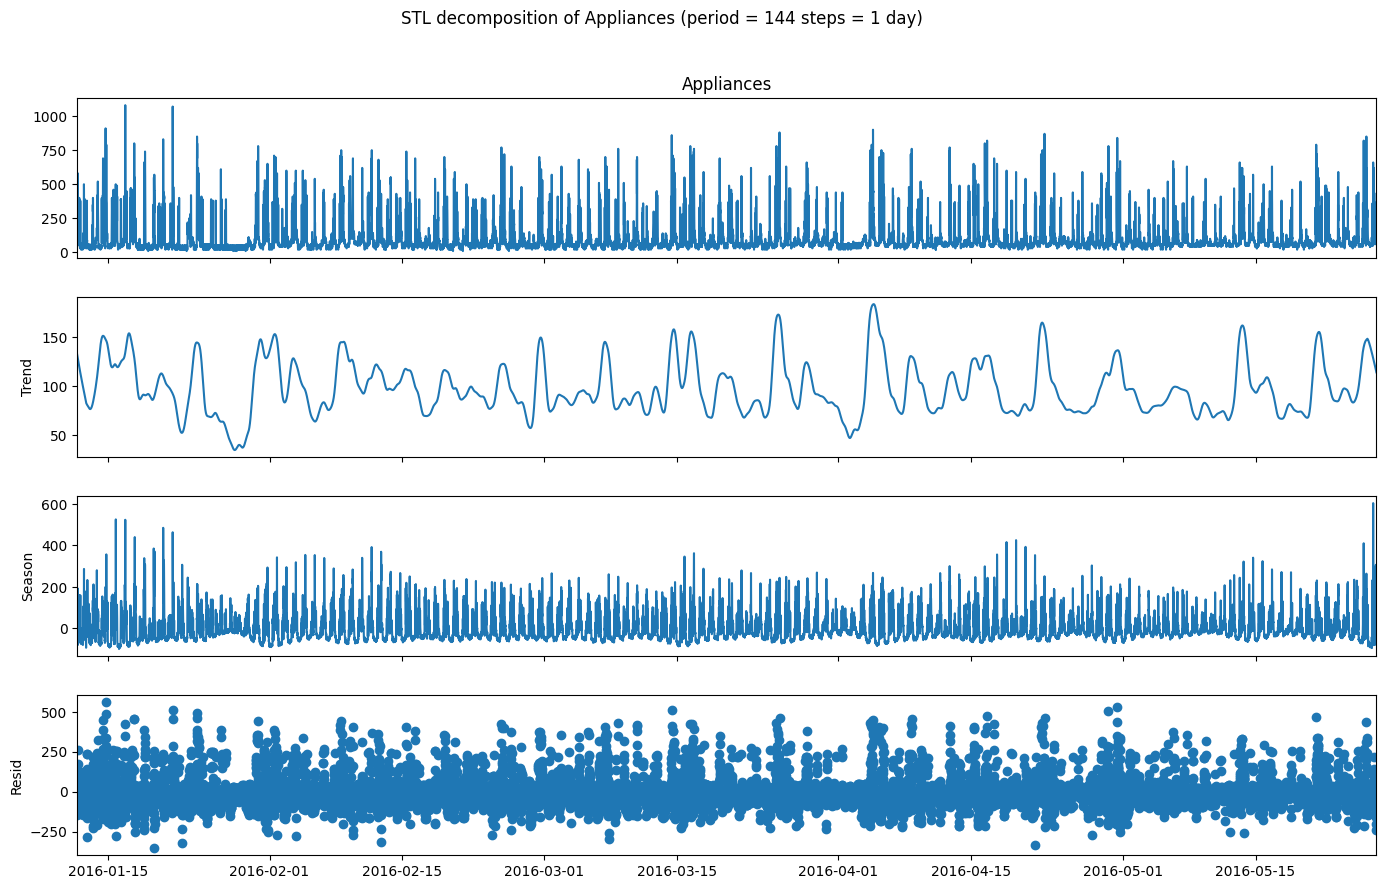

Daily seasonal component: -99 to 604 Wh
Trend: 35 to 184 Wh


In [85]:
from statsmodels.tsa.seasonal import STL

stl = STL(df["Appliances"], period=144).fit()
fig = stl.plot()
fig.set_size_inches(15, 9)
fig.suptitle("STL decomposition of Appliances (period = 144 steps = 1 day)", y=1.02)
plt.show()

print(f"Daily seasonal component: {stl.seasonal.min():.0f} to {stl.seasonal.max():.0f} Wh")
print(f"Trend: {stl.trend.min():.0f} to {stl.trend.max():.0f} Wh")

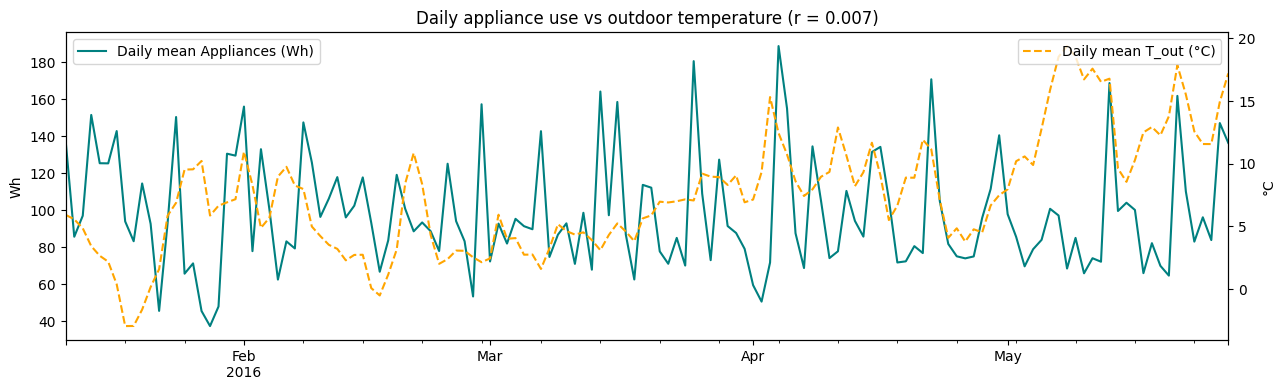

In [86]:
daily = df[["Appliances", "T_out"]].resample("D").mean()
r = daily["Appliances"].corr(daily["T_out"])

ax = daily["Appliances"].plot(figsize=(15, 4), color="teal", label="Daily mean Appliances (Wh)")
ax2 = ax.twinx()
daily["T_out"].plot(ax=ax2, color="orange", linestyle="--", label="Daily mean T_out (°C)")
ax.set(title=f"Daily appliance use vs outdoor temperature (r = {r:.3f})", ylabel="Wh", xlabel="")
ax2.set_ylabel("°C")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.show()

In [87]:
from pathlib import Path
Path("data").mkdir(parents=True, exist_ok=True)
df.to_parquet("data/eda.parquet")